# Wildfire Susceptibility Mapping — Selon la Methode Paper India
- Utilisation du dataSet reconstitué
- Spliting selon le ratio 1:1
- Entraînent des models
- Evaluation (Utilisation de Metric AUC et PR AUC pour comparaison future avec les autres methode implémenté)

1. Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay,
    precision_recall_curve, auc
)
from xgboost import XGBClassifier

2. Montage Google Drive

In [2]:
drive.mount('/content/gdrive')

Mounted at /content/gdrive


3. Chargement des données

In [3]:
csv_path  = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/datasetPaperIndian.csv"
dfDataSet = pd.read_csv(csv_path)

print("Dataset chargé :", dfDataSet.shape)
print(dfDataSet.columns.tolist())
dfDataSet.head()

Dataset chargé : (89198, 13)
['latitude', 'longitude', 'landcover', 'in_fire', 'dist_fire_km', 'mean_slope', 'mean_twi', 'mean_aspect', 'ndvi_final', 'mean_LST_celsius', 'dist_residentiel_m', 'dist_route_m', 'Elevation']


,latitude,longitude,landcover,in_fire,dist_fire_km,mean_slope,mean_twi,mean_aspect,ndvi_final,mean_LST_celsius,dist_residentiel_m,dist_route_m,Elevation
0,36.987823,-7.963676,210,0,17.197693,0.571321,6.447956,196.846283,0.686275,21.902494,1846.893734,471.899104,0.0
1,36.994129,-8.952213,110,0,23.004464,2.499209,3.489216,178.080078,0.866667,15.699432,1447.688717,170.582454,0.0
2,36.996850,-7.974890,210,0,16.054264,1.402498,7.057358,179.751862,0.889725,22.155281,457.222141,122.542919,0.0
3,37.003139,-8.952309,210,0,22.375234,2.263847,3.493453,290.926086,0.866667,16.453320,715.827701,364.845213,0.0
4,37.003216,-8.941076,210,0,21.596848,2.697602,4.360210,171.431244,0.918118,18.861568,293.616377,242.791353,0.0


4. Préparation & ratio 1:1

In [4]:
df_clean = dfDataSet.dropna(subset=['in_fire']).copy()

print("Distribution originale :")
print(df_clean['in_fire'].value_counts())
print(df_clean['in_fire'].value_counts(normalize=True))

# Équilibrage 1:1
fire            = df_clean[df_clean['in_fire'] == 1]
no_fire         = df_clean[df_clean['in_fire'] == 0]
no_fire_sampled = no_fire.sample(n=len(fire), random_state=42)
df_balanced     = pd.concat([fire, no_fire_sampled]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nAprès équilibrage 1:1 :")
print(f"  Feux     : {len(fire)}")
print(f"  Non-feux : {len(no_fire_sampled)}")
print(f"  Total    : {len(df_balanced)}")

# Features et target
X = df_balanced.drop(columns=['in_fire', 'dist_fire_km', 'latitude', 'longitude'])
y = df_balanced['in_fire'].astype(int)
X = X.select_dtypes(include=[np.number])

print(f"\nFeatures utilisées ({len(X.columns)}) :")
print(list(X.columns))

Distribution originale :
in_fire
0    80336
1     8862
Name: count, dtype: int64
in_fire
0    0.900648
1    0.099352
Name: proportion, dtype: float64

Après équilibrage 1:1 :
  Feux     : 8862
  Non-feux : 8862
  Total    : 17724

Features utilisées (9) :
['landcover', 'mean_slope', 'mean_twi', 'mean_aspect', 'ndvi_final', 'mean_LST_celsius', 'dist_residentiel_m', 'dist_route_m', 'Elevation']


5. Split 70/30 + Prétraitement

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

y_train = np.array(y_train).astype(int)
y_test  = np.array(y_test).astype(int)

# Imputation médiane
imputer     = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),      columns=X.columns)

# Centrage + normalisation
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_imp)
X_test_sc  = scaler.transform(X_test_imp)

print(f"Train : {X_train_sc.shape[0]} échantillons ({X_train_sc.shape[0]/len(X)*100:.1f}%)")
print(f"Test  : {X_test_sc.shape[0]}  échantillons ({X_test_sc.shape[0]/len(X)*100:.1f}%)")

Train : 12406 échantillons (70.0%)
Test  : 5318  échantillons (30.0%)


6. Définition des modèles & configuration

In [6]:
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=500,
        max_features=8,
        max_depth=15,
        min_samples_leaf=5,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ),
    'SVM': SVC(
        kernel='rbf',
        C=1,
        probability=True,
        random_state=42
    ),
    'XGBoost': XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.6,
        gamma=1,
        min_child_weight=5,
        reg_alpha=0.1,
        reg_lambda=1.5,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
}

# Paramètres de visualisation
colors_all = {
    'SVM':           'steelblue',
    'Random Forest': 'darkorange',
    'XGBoost':       'crimson',
}
cmaps_cm = {
    'SVM':           'Blues',
    'Random Forest': 'Oranges',
    'XGBoost':       'Reds',
}
all_models   = ['SVM', 'Random Forest', 'XGBoost']
metrics_list = ['Accuracy', 'Sensitivity', 'Specificity', 'AUC', 'PR_AUC']

print("Modèles définis :", all_models)

Modèles définis : ['SVM', 'Random Forest', 'XGBoost']


7. Fonction de calcul des métriques


In [7]:
def compute_metrics(y_true, y_pred, y_proba):
    y_true  = np.array(y_true).astype(int)
    y_pred  = np.array(y_pred).astype(int)
    y_proba = np.array(y_proba)

    tn, fp, fn, tp    = confusion_matrix(y_true, y_pred).ravel()
    prec, rec, _      = precision_recall_curve(y_true, y_proba)
    pr_auc            = float(np.round(auc(rec, prec), 3))

    return {
        'Accuracy':    float(np.round(accuracy_score(y_true, y_pred), 3)),
        'Sensitivity': float(np.round(tp / (tp + fn), 3)),
        'Specificity': float(np.round(tn / (tn + fp), 3)),
        'AUC':         float(np.round(roc_auc_score(y_true, y_proba), 3)),
        'PR_AUC':      pr_auc,
    }

8. Entraînement des modèles


In [8]:
results_calibration = {}
results_validation  = {}
trained_models      = {}
probas_test         = {}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"  {name.upper()}")
    print(f"{'='*50}")

    model.fit(X_train_sc, y_train)
    trained_models[name] = model

    # Calibration (train)
    y_pred_train  = model.predict(X_train_sc)
    y_proba_train = model.predict_proba(X_train_sc)[:, 1]
    results_calibration[name] = compute_metrics(y_train, y_pred_train, y_proba_train)

    # Validation (test)
    y_pred_test  = model.predict(X_test_sc)
    y_proba_test = model.predict_proba(X_test_sc)[:, 1]
    results_validation[name] = compute_metrics(y_test, y_pred_test, y_proba_test)
    probas_test[name]        = y_proba_test

    print(f"  Calibration : {results_calibration[name]}")
    print(f"  Validation  : {results_validation[name]}")


  RANDOM FOREST
  Calibration : {'Accuracy': 0.906, 'Sensitivity': 0.921, 'Specificity': 0.891, 'AUC': 0.975, 'PR_AUC': 0.974}
  Validation  : {'Accuracy': 0.741, 'Sensitivity': 0.731, 'Specificity': 0.751, 'AUC': 0.822, 'PR_AUC': 0.801}

  SVM
  Calibration : {'Accuracy': 0.731, 'Sensitivity': 0.725, 'Specificity': 0.737, 'AUC': 0.795, 'PR_AUC': 0.757}
  Validation  : {'Accuracy': 0.711, 'Sensitivity': 0.71, 'Specificity': 0.712, 'AUC': 0.77, 'PR_AUC': 0.733}

  XGBOOST
  Calibration : {'Accuracy': 0.774, 'Sensitivity': 0.759, 'Specificity': 0.788, 'AUC': 0.86, 'PR_AUC': 0.854}
  Validation  : {'Accuracy': 0.721, 'Sensitivity': 0.703, 'Specificity': 0.739, 'AUC': 0.798, 'PR_AUC': 0.782}


9. Tableau comparatif — Calibration vs Validation


In [9]:
print("\n" + "="*75)
print("  TABLE COMPARAISON — Calibration vs Validation")
print("="*75)
print(f"\n{'Phase':<15} {'Métrique':<15}", end="")
for name in all_models:
    print(f"{name:>16}", end="")
print()
print("-"*75)

for phase, results in [("Calibration", results_calibration),
                        ("Validation",  results_validation)]:
    for m in metrics_list:
        print(f"{phase:<15} {m:<15}", end="")
        for name in all_models:
            print(f"{results[name][m]:>16.3f}", end="")
        print()
    print("-"*75)

print("\n  Référence papier (Uthappa et al.) :")
print("  SVM AUC=0.974 | RF AUC=0.995 | XGB AUC=0.994")


  TABLE COMPARAISON — Calibration vs Validation

Phase           Métrique                    SVM   Random Forest         XGBoost
---------------------------------------------------------------------------
Calibration     Accuracy                  0.731           0.906           0.774
Calibration     Sensitivity               0.725           0.921           0.759
Calibration     Specificity               0.737           0.891           0.788
Calibration     AUC                       0.795           0.975           0.860
Calibration     PR_AUC                    0.757           0.974           0.854
---------------------------------------------------------------------------
Validation      Accuracy                  0.711           0.741           0.721
Validation      Sensitivity               0.710           0.731           0.703
Validation      Specificity               0.712           0.751           0.739
Validation      AUC                       0.770           0.822           0.79

10. Matrices de confusion — Validation


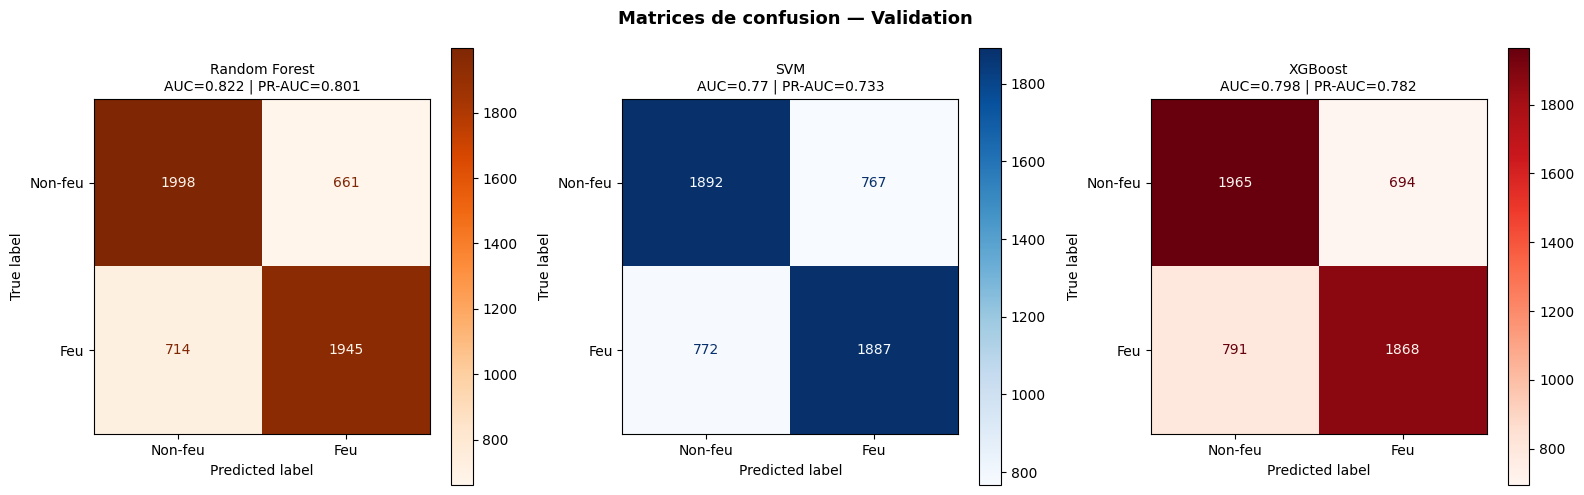

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Matrices de confusion — Validation", fontsize=13, fontweight='bold')

for i, (name, model) in enumerate(trained_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test_sc),
        display_labels=['Non-feu', 'Feu'],
        cmap=cmaps_cm[name], ax=axes[i]
    )
    val = results_validation[name]
    axes[i].set_title(f"{name}\nAUC={val['AUC']} | PR-AUC={val['PR_AUC']}", fontsize=10)

plt.tight_layout()
plt.show()

11. Courbes ROC & Précision-Rappel — Validation


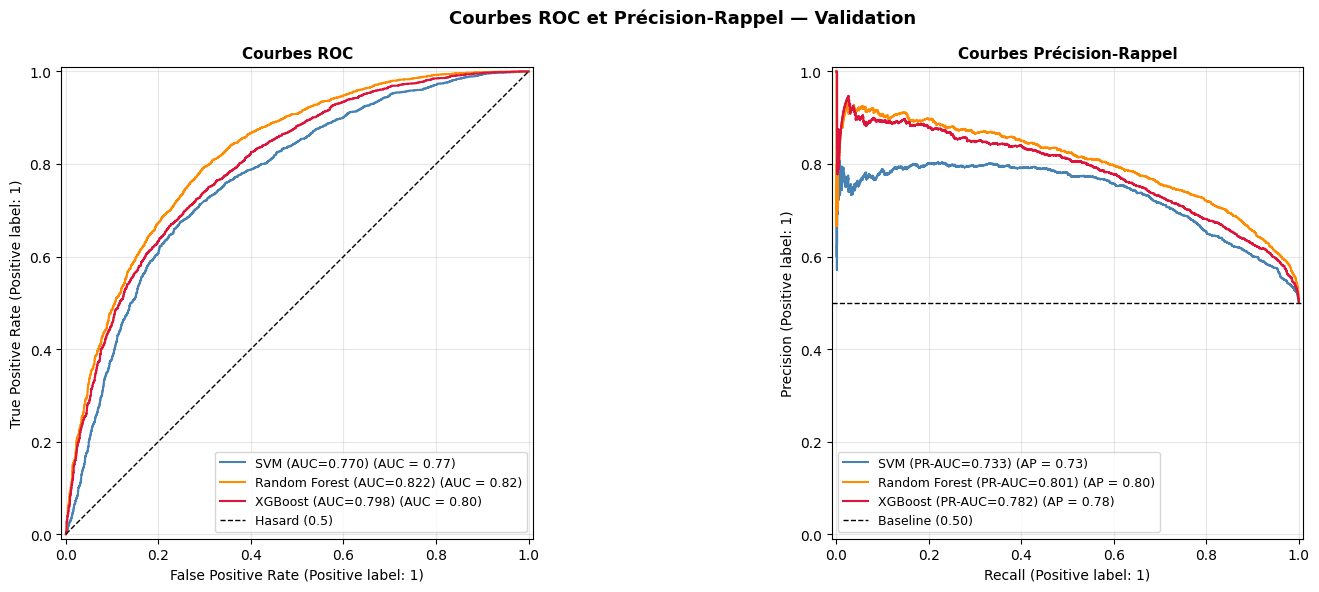

In [11]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Courbes ROC et Précision-Rappel — Validation", fontsize=13, fontweight='bold')

for name in all_models:
    RocCurveDisplay.from_predictions(
        y_test, probas_test[name],
        name=f"{name} (AUC={results_validation[name]['AUC']:.3f})",
        color=colors_all[name], ax=ax_roc
    )
    PrecisionRecallDisplay.from_predictions(
        y_test, probas_test[name],
        name=f"{name} (PR-AUC={results_validation[name]['PR_AUC']:.3f})",
        color=colors_all[name], ax=ax_pr
    )

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, label='Hasard (0.5)')
ax_roc.set_title("Courbes ROC", fontsize=11, fontweight='bold')
ax_roc.grid(alpha=0.3)
ax_roc.legend(fontsize=9)

baseline = y_test.sum() / len(y_test)
ax_pr.axhline(y=baseline, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline:.2f})')
ax_pr.set_title("Courbes Précision-Rappel", fontsize=11, fontweight='bold')
ax_pr.grid(alpha=0.3)
ax_pr.legend(fontsize=9)

plt.tight_layout()
plt.show()

12. Importance des variables — RF & XGBoost


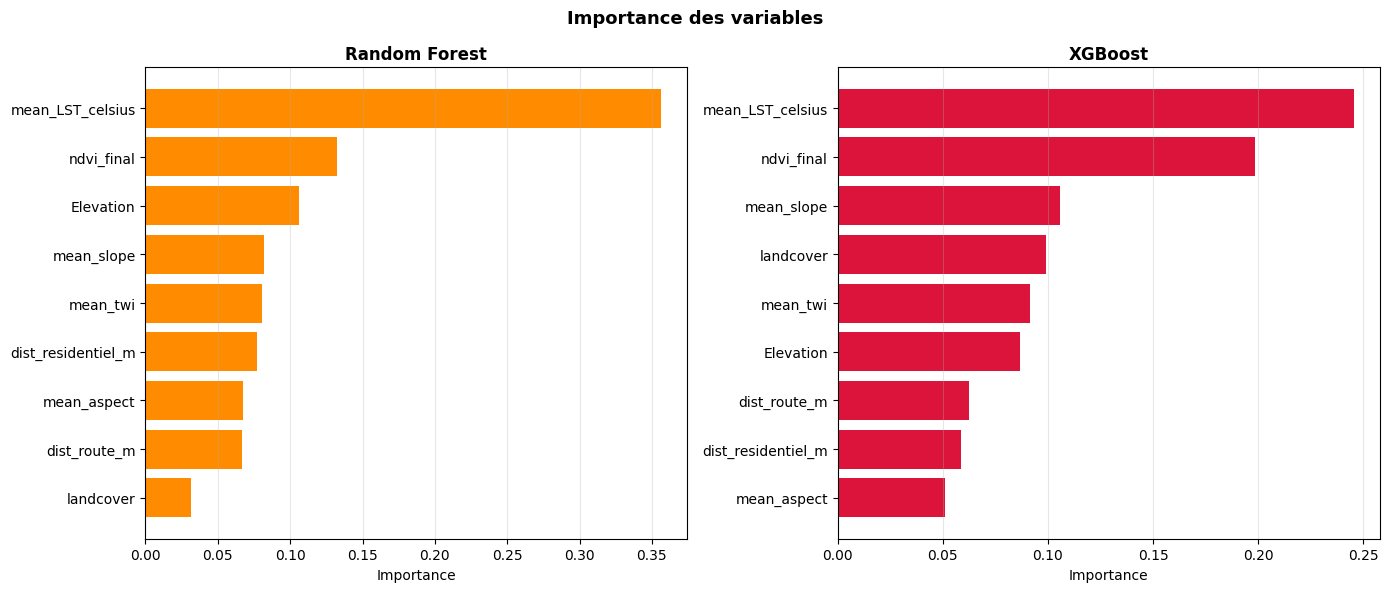

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Importance des variables", fontsize=13, fontweight='bold')

feat_rf = pd.Series(
    trained_models['Random Forest'].feature_importances_, index=X.columns
).sort_values(ascending=True).tail(15)
ax1.barh(feat_rf.index, feat_rf.values, color='darkorange')
ax1.set_title("Random Forest", fontweight='bold')
ax1.set_xlabel("Importance")
ax1.grid(axis='x', alpha=0.3)

feat_xgb = pd.Series(
    trained_models['XGBoost'].feature_importances_, index=X.columns
).sort_values(ascending=True).tail(15)
ax2.barh(feat_xgb.index, feat_xgb.values, color='crimson')
ax2.set_title("XGBoost", fontweight='bold')
ax2.set_xlabel("Importance")
ax2.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

13. Prédiction sur le dataset complet — Préparation


In [13]:
df_all = dfDataSet.dropna(subset=['in_fire']).copy()
X_all  = df_all.drop(columns=['in_fire', 'dist_fire_km', 'latitude', 'longitude'])
X_all  = X_all.select_dtypes(include=[np.number])
y_all  = np.array(df_all['in_fire']).astype(int)

lat_all = df_all['latitude'].values
lon_all = df_all['longitude'].values

X_all_imp = pd.DataFrame(imputer.transform(X_all), columns=X_all.columns)
X_all_sc  = scaler.transform(X_all_imp)

print(f"Total points : {len(y_all)}")
print(f"Feux réels   : {y_all.sum()} ({y_all.sum()/len(y_all)*100:.1f}%)")
print(f"Non-feux     : {(y_all==0).sum()} ({(y_all==0).sum()/len(y_all)*100:.1f}%)")

results_all = {}
probas_all  = {}

for name, model in trained_models.items():
    y_pred_all        = model.predict(X_all_sc)
    y_proba_all       = model.predict_proba(X_all_sc)[:, 1]
    results_all[name] = compute_metrics(y_all, y_pred_all, y_proba_all)
    probas_all[name]  = y_proba_all

Total points : 89198
Feux réels   : 8862 (9.9%)
Non-feux     : 80336 (90.1%)


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


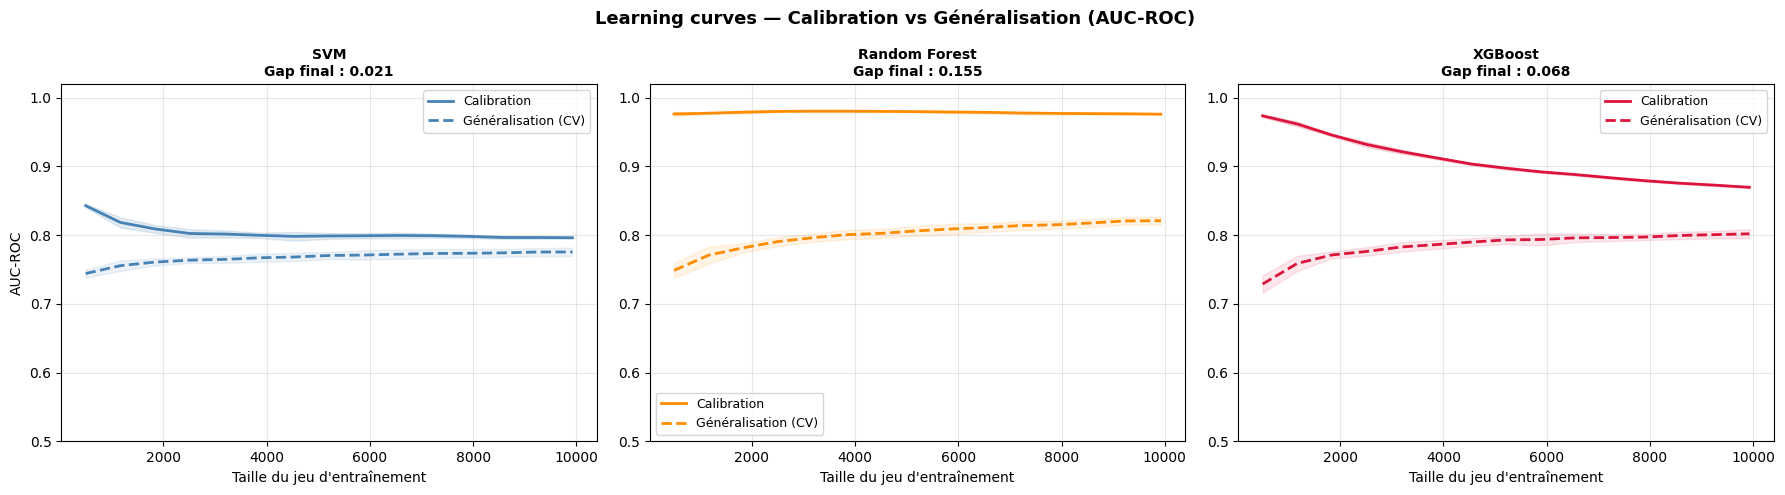

In [14]:
# 13-bis. Learning curves — Calibration vs Généralisation

from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Learning curves — Calibration vs Généralisation (AUC-ROC)", fontsize=13, fontweight='bold')

train_sizes = np.linspace(0.05, 1.0, 15)

for i, name in enumerate(all_models):
    model = trained_models[name]
    color = colors_all[name]

    train_sizes_abs, train_scores, val_scores = learning_curve(
        model,
        X_train_sc, y_train,
        train_sizes=train_sizes,
        cv=5,
        scoring='roc_auc',
        n_jobs=-1,
        shuffle=True,
        random_state=42
    )

    train_mean = train_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    val_mean   = val_scores.mean(axis=1)
    val_std    = val_scores.std(axis=1)

    ax = axes[i]

    # Courbe calibration (train)
    ax.plot(train_sizes_abs, train_mean, color=color, lw=2, label='Calibration')
    ax.fill_between(train_sizes_abs,
                    train_mean - train_std,
                    train_mean + train_std,
                    alpha=0.15, color=color)

    # Courbe généralisation (val)
    ax.plot(train_sizes_abs, val_mean, color=color, lw=2, linestyle='--', label='Généralisation (CV)')
    ax.fill_between(train_sizes_abs,
                    val_mean - val_std,
                    val_mean + val_std,
                    alpha=0.10, color=color)

    # Gap final (overfitting indicator)
    gap = train_mean[-1] - val_mean[-1]
    ax.set_title(f"{name}\nGap final : {gap:.3f}", fontsize=10, fontweight='bold')
    ax.set_xlabel("Taille du jeu d'entraînement")
    ax.set_ylabel("AUC-ROC" if i == 0 else "")
    ax.set_ylim(0.5, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

14. Tableau métriques — Dataset complet


In [15]:
print("\n" + "="*75)
print("  MÉTRIQUES — Dataset complet")
print("="*75)
print(f"\n{'Métrique':<15}", end="")
for name in all_models:
    print(f"{name:>16}", end="")
print()
print("-"*75)
for m in metrics_list:
    print(f"{m:<15}", end="")
    for name in all_models:
        print(f"{results_all[name][m]:>16.3f}", end="")
    print()
print("="*75)

print("\n" + "="*75)
print("  COMPARAISON — Validation (30%) vs Dataset complet (100%)")
print("="*75)
for name in all_models:
    print(f"\n── {name} ──────────────────────────────────")
    print(f"  {'Métrique':<15} {'Validation':>12} {'Complet':>12}")
    print(f"  {'-'*42}")
    for m in metrics_list:
        print(f"  {m:<15} {results_validation[name][m]:>12.3f} {results_all[name][m]:>12.3f}")
print("="*75)


  MÉTRIQUES — Dataset complet

Métrique                    SVM   Random Forest         XGBoost
---------------------------------------------------------------------------
Accuracy                  0.717           0.769           0.742
Sensitivity               0.720           0.864           0.742
Specificity               0.716           0.758           0.742
AUC                       0.776           0.887           0.820
PR_AUC                    0.244           0.466           0.338

  COMPARAISON — Validation (30%) vs Dataset complet (100%)

── SVM ──────────────────────────────────
  Métrique          Validation      Complet
  ------------------------------------------
  Accuracy               0.711        0.717
  Sensitivity            0.710        0.720
  Specificity            0.712        0.716
  AUC                    0.770        0.776
  PR_AUC                 0.733        0.244

── Random Forest ──────────────────────────────────
  Métrique          Validation      Complet

15. Matrices de confusion — Dataset complet


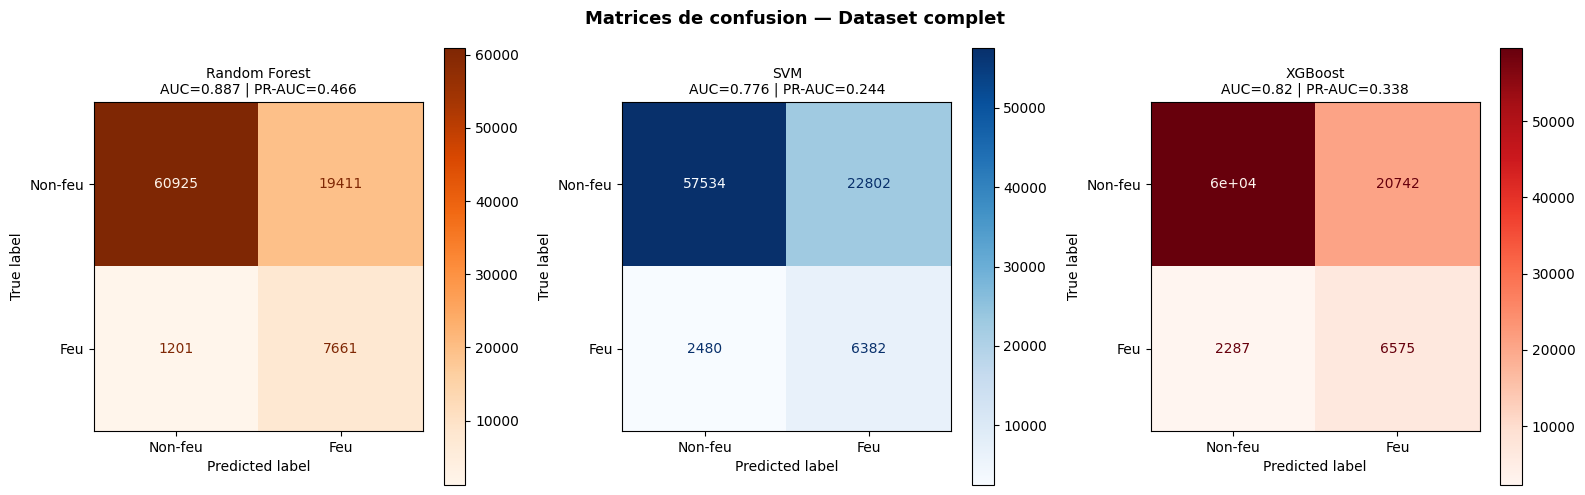

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Matrices de confusion — Dataset complet", fontsize=13, fontweight='bold')

for i, (name, model) in enumerate(trained_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_all, model.predict(X_all_sc),
        display_labels=['Non-feu', 'Feu'],
        cmap=cmaps_cm[name], ax=axes[i]
    )
    r = results_all[name]
    axes[i].set_title(f"{name}\nAUC={r['AUC']} | PR-AUC={r['PR_AUC']}", fontsize=10)

plt.tight_layout()
plt.show()

16. Courbes ROC & Précision-Rappel — Dataset complet


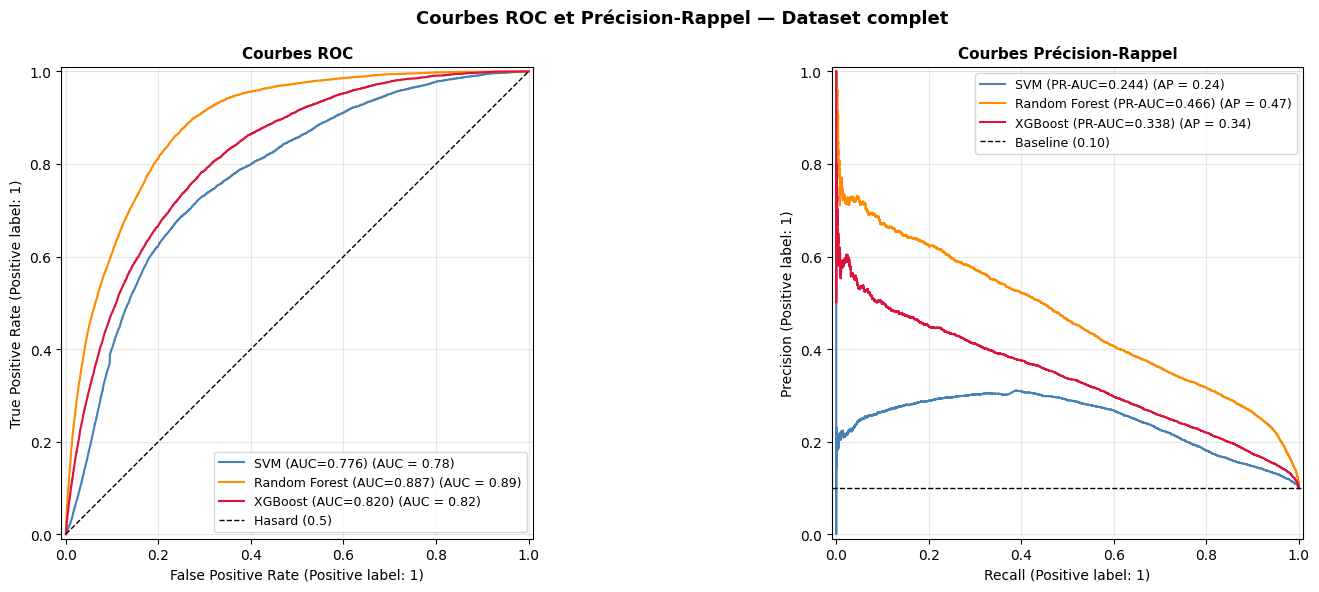

In [17]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Courbes ROC et Précision-Rappel — Dataset complet", fontsize=13, fontweight='bold')

for name in all_models:
    RocCurveDisplay.from_predictions(
        y_all, probas_all[name],
        name=f"{name} (AUC={results_all[name]['AUC']:.3f})",
        color=colors_all[name], ax=ax_roc
    )
    PrecisionRecallDisplay.from_predictions(
        y_all, probas_all[name],
        name=f"{name} (PR-AUC={results_all[name]['PR_AUC']:.3f})",
        color=colors_all[name], ax=ax_pr
    )

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, label='Hasard (0.5)')
ax_roc.set_title("Courbes ROC", fontsize=11, fontweight='bold')
ax_roc.grid(alpha=0.3)
ax_roc.legend(fontsize=9)

baseline_all = y_all.sum() / len(y_all)
ax_pr.axhline(y=baseline_all, color='k', linestyle='--', lw=1,
              label=f'Baseline ({baseline_all:.2f})')
ax_pr.set_title("Courbes Précision-Rappel", fontsize=11, fontweight='bold')
ax_pr.grid(alpha=0.3)
ax_pr.legend(fontsize=9)

plt.tight_layout()
plt.show()

17. Carte de probabilité de feu — Dataset complet


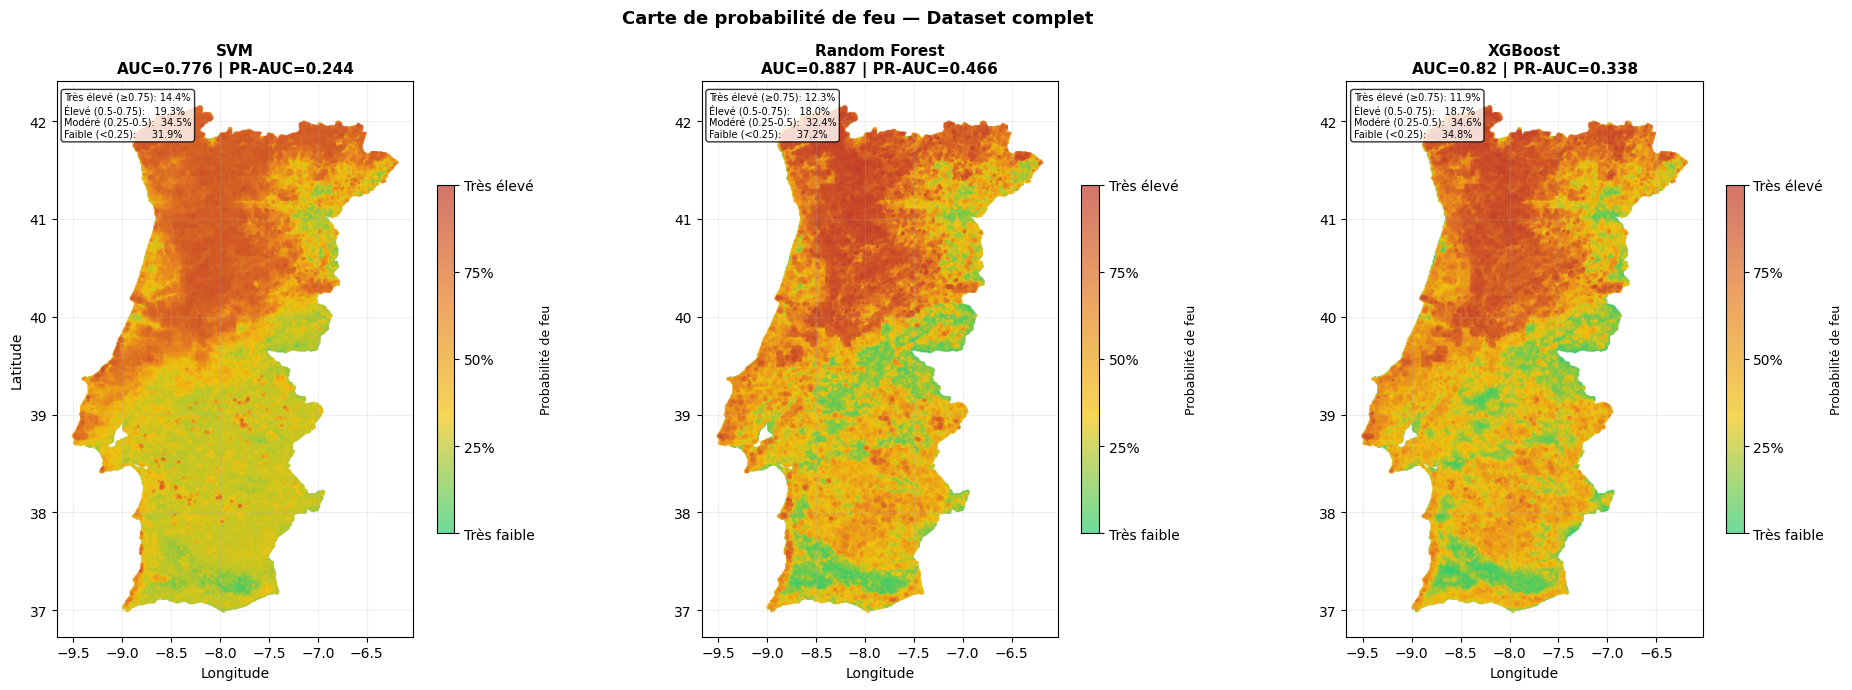

In [18]:
cmap_fire = LinearSegmentedColormap.from_list(
    'fire_risk', ['#2ECC71', '#F1C40F', '#E67E22', '#C0392B'], N=256
)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle("Carte de probabilité de feu — Dataset complet",
             fontsize=13, fontweight='bold')

for i, name in enumerate(all_models):
    proba = probas_all[name]
    order = np.argsort(proba)

    sc = axes[i].scatter(
        lon_all[order], lat_all[order],
        c=proba[order], cmap=cmap_fire,
        vmin=0, vmax=1, s=2, alpha=0.7
    )
    cbar = plt.colorbar(sc, ax=axes[i], fraction=0.03, pad=0.04)
    cbar.set_label('Probabilité de feu', fontsize=9)
    cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
    cbar.set_ticklabels(['Très faible', '25%', '50%', '75%', 'Très élevé'])

    r = results_all[name]
    axes[i].set_title(
        f"{name}\nAUC={r['AUC']} | PR-AUC={r['PR_AUC']}",
        fontsize=11, fontweight='bold'
    )
    axes[i].set_xlabel("Longitude")
    if i == 0:
        axes[i].set_ylabel("Latitude")
    axes[i].set_aspect('equal')
    axes[i].grid(alpha=0.2)

    n_total = len(proba)
    textstr = (
        f"Très élevé (≥0.75): {(proba>=0.75).sum()/n_total*100:.1f}%\n"
        f"Élevé (0.5-0.75):   {((proba>=0.5)&(proba<0.75)).sum()/n_total*100:.1f}%\n"
        f"Modéré (0.25-0.5):  {((proba>=0.25)&(proba<0.5)).sum()/n_total*100:.1f}%\n"
        f"Faible (<0.25):     {(proba<0.25).sum()/n_total*100:.1f}%"
    )
    axes[i].text(0.02, 0.98, textstr, transform=axes[i].transAxes, fontsize=7,
                 verticalalignment='top',
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()


In [19]:
# ============================================================
# MÉTRIQUES COMPARATIVES — Format compatible notre solution
# ============================================================

print("\n" + "="*65)
print("  MÉTRIQUES COMPARATIVES")
print("="*65)
print(f"\n{'Metric':<25} {'SVM':>10} {'RF':>10} {'XGBoost':>10}")
print("-"*65)

for name in all_models:
    cal  = results_calibration[name]
    val  = results_validation[name]

    roc_test  = val['AUC']
    pr_test   = val['PR_AUC']
    gap       = round(cal['AUC'] - val['AUC'], 3)   # generalisation gap
    inner_ap  = cal['PR_AUC']                        # inner AP = train PR-AUC

metrics_compare = {}
for name in all_models:
    cal = results_calibration[name]
    val = results_validation[name]
    metrics_compare[name] = {
        'ROC-AUC (test)':      val['AUC'],
        'PR-AUC (test)':       val['PR_AUC'],
        'Generalisation gap':  round(cal['AUC'] - val['AUC'], 3),
        'Inner AP':            cal['PR_AUC'],
        'Avg. trees':          'N/A'
    }

rows = ['ROC-AUC (test)', 'PR-AUC (test)', 'Generalisation gap', 'Inner AP', 'Avg. trees']
for row in rows:
    print(f"{row:<25}", end="")
    for name in all_models:
        val = metrics_compare[name][row]
        if isinstance(val, float):
            print(f"{val:>10.3f}", end="")
        else:
            print(f"{val:>10}", end="")
    print()

print("="*65)
print("\n  Notre solution (LightGBM + spatial CV) :")
print("  ROC-AUC=0.846±0.043 | PR-AUC=0.423±0.163 | Gap=0.042±0.048 | Inner AP=0.495±0.096 | Trees=29")


  MÉTRIQUES COMPARATIVES

Metric                           SVM         RF    XGBoost
-----------------------------------------------------------------
ROC-AUC (test)                0.770     0.822     0.798
PR-AUC (test)                 0.733     0.801     0.782
Generalisation gap            0.025     0.153     0.062
Inner AP                      0.757     0.974     0.854
Avg. trees                      N/A       N/A       N/A

  Notre solution (LightGBM + spatial CV) :
  ROC-AUC=0.846±0.043 | PR-AUC=0.423±0.163 | Gap=0.042±0.048 | Inner AP=0.495±0.096 | Trees=29
